# 05. Временные и пространственные зависимости

Ноутбук отвечает на вопросы, от которых зависит выбор моделей, до запуска самих моделей:

1. Корректно ли выровнены по времени новые данные (прогноз погоды, закрытия).
2. Какой простой прогноз — честная нижняя планка.
3. Насколько отклонения спроса от нормы «помнят» себя и насколько они общие для всего города.
4. **Пространственные зависимости:** помогают ли соседи станции предсказать её спрос, на каком горизонте
   и какой граф (линии, расстояние, OD, динамический OD) описывает связь лучше.
5. Сила внешних факторов: погода (факт и прогноз), праздники, события на площадках.
6. Закрытия станций: что из них предсказуемо заранее.
7. Дрейф: насколько тест отличается от обучения по станциям.

Всё считается по обучающему периоду, кроме мест, где явно указано val/test.
«Норма» везде — медиана того же часа той же станции за 4 предыдущие недели (известна в 00:00 дня прогноза).

In [1]:
import sys, json, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import PROCESSED, RAW, TRAIN_END, VAL_END

COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK2, MUTED, GRID = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_rows", 60, "display.max_colwidth", 60)

def check(ok, msg):
    print(("OK          " if ok else "ВНИМАНИЕ    ") + msg)

def corr_rows(a, b):
    """Корреляция по столбцам двух матриц (час × станция) с пропусками; среднее по станциям."""
    return np.nanmean([pd.Series(a[:, i]).corr(pd.Series(b[:, i])) for i in range(a.shape[1])])

LAB, GRAPH = PROCESSED / "lab", PROCESSED / "graph"
Y = pd.read_parquet(LAB / "ridership_wide.parquet").astype("float32")
C = pd.read_parquet(LAB / "closed_wide.parquet")
X = pd.read_parquet(LAB / "covariates_time.parquet")
FC = pd.read_parquet(LAB / "weather_forecast_city.parquet")
st = pd.read_parquet(LAB / "station_static.parquet")
st["station_complex_id"] = st["station_complex_id"].astype(str)
name = st.set_index("station_complex_id")["station_complex"]
cal = pd.read_parquet(PROCESSED / "calendar_ext.parquet").set_index("transit_timestamp")
split = pd.Series("train", index=Y.index)
split[Y.index > TRAIN_END] = "val"
split[Y.index > VAL_END] = "test"
OPEN = ~C.values
print(f"Y {Y.shape}, прогноз погоды {FC.shape}, станций {len(st)}")

Y (32708, 424), прогноз погоды (23952, 9), станций 424


## 1. Выравнивание новых данных по времени

In [2]:
for nm, w in [("факт", X), ("прогноз", FC)]:
    prof = w["temperature_2m"].groupby(w.index.hour).mean()
    check(prof.idxmax() in (13, 14, 15, 16), f"погода ({nm}): максимум температуры в {prof.idxmax()}:00 по местному времени")
lag_corr = {k: X["temperature_2m"].corr(FC["temperature_2m"].shift(k)) for k in range(-3, 4)}
check(max(lag_corr, key=lag_corr.get) == 0, f"прогноз и факт лучше всего совпадают без сдвига: {max(lag_corr, key=lag_corr.get)} ч")

miss = FC.isna().groupby(FC.index.to_period("M")).mean()
miss = miss[miss.max(axis=1) > 0.01][["temperature_2m", "precipitation", "rain"]]
print("\nДоля пропусков прогноза по месяцам (только месяцы с пропусками):")
display((miss * 100).round(0).astype(int).astype(str) + "%")
check(FC.loc[FC.index > TRAIN_END, ["temperature_2m", "precipitation", "snowfall"]].notna().all().all(),
      "в val/test прогноз температуры и осадков без пропусков")
check(FC["rain"].isna().mean() < 0.1,
      f"прогноз rain заполнен на {FC['rain'].notna().mean():.0%} — использовать precipitation и snowfall, rain не брать")

OK          погода (факт): максимум температуры в 15:00 по местному времени
OK          погода (прогноз): максимум температуры в 15:00 по местному времени
OK          прогноз и факт лучше всего совпадают без сдвига: 0 ч

Доля пропусков прогноза по месяцам (только месяцы с пропусками):


,temperature_2m,precipitation,rain
transit_timestamp,,,
2024-01,59%,59%,100%
2024-02,96%,96%,100%
2024-03,0%,0%,100%
2024-04,0%,0%,100%
2024-05,0%,0%,100%
2024-06,0%,0%,100%
2024-07,0%,0%,100%
2024-08,0%,0%,100%
2024-09,0%,0%,100%


OK          в val/test прогноз температуры и осадков без пропусков
ВНИМАНИЕ    прогноз rain заполнен на 66% — использовать precipitation и snowfall, rain не брать


## 2. Нижняя планка: какой наивный прогноз честный

Прогноз строится в 00:00 на сутки, значит доступны все часы до конца вчерашнего дня. Сравниваем правила
«вчера тот же час», «неделю назад», среднее и медиану того же часа за 4 недели. Лаги, попавшие на закрытый день,
не используются; метрика — WAPE по открытым станциям.

In [3]:
Yv = Y.values
def lag(k):
    out = np.full_like(Yv, np.nan)
    out[k:] = Yv[:-k]
    ok = np.zeros_like(OPEN); ok[k:] = OPEN[:-k]
    out[~ok] = np.nan
    return out

def wape(p, mask):
    m = mask & ~np.isnan(p)
    return np.abs(Yv[m] - p[m]).sum() / Yv[m].sum()

weeks = np.stack([lag(168 * k) for k in (1, 2, 3, 4)])
with np.errstate(all="ignore"):
    NORM = np.nanmedian(weeks, axis=0)
    MEAN4 = np.nanmean(weeks, axis=0)
rules = {"вчера тот же час": lag(24), "неделю назад": lag(168), "среднее 4 недель": MEAN4, "медиана 4 недель": NORM}
del weeks
tab = pd.DataFrame({r: {s: wape(p, OPEN & (split.values == s)[:, None]) for s in ["train", "val", "test"]}
                    for r, p in rules.items()}).T
display(tab.round(4))
check(tab.loc["медиана 4 недель", "test"] < tab.loc["неделю назад", "test"],
      "медиана 4 недель сильнее «неделю назад» — её и брать нижней планкой")

,train,val,test
вчера тот же час,0.2485,0.2388,0.2345
неделю назад,0.1531,0.1349,0.1425
среднее 4 недель,0.1462,0.1129,0.1345
медиана 4 недель,0.1416,0.1076,0.1299


OK          медиана 4 недель сильнее «неделю назад» — её и брать нижней планкой


## 3. Отклонение дня от нормы: память и общая городская составляющая

Для каждой станции и дня — логарифм отношения фактических входов к норме. Смотрим, насколько это отклонение
повторяется на следующий день и какая его доля общая для всего города (погода, праздники, общий ритм).

In [4]:
day = Y.index.normalize()
okn = OPEN & ~np.isnan(NORM)
Yd = pd.DataFrame(np.where(okn, Yv, 0)).groupby(day).sum()
Nd = pd.DataFrame(np.where(okn, NORM, 0)).groupby(day).sum()
R = np.log((Yd + 50) / (Nd + 50)).where(Nd >= 500)
Rt = R[(R.index >= "2023-03-01") & (R.index <= TRAIN_END)]
city = Rt.mean(axis=1)
acf = {k: np.nanmean([Rt[c].autocorr(k) for c in Rt.columns]) for k in [1, 2, 3, 7, 14]}
share_city = np.nanmean([Rt[c].corr(city) ** 2 for c in Rt.columns])
print("Автокорреляция дневного отклонения станции, лаг в днях:", {k: round(v, 2) for k, v in acf.items()})
print(f"Доля дисперсии отклонения станции, общая с городом (R²): {share_city:.2f}")

# Потолок: сколько ошибки уходит, если знать точный уровень дня (оракул)
te = split.values == "test"
Yt, Nt, Mt = Yv[te], NORM[te], okn[te]
dt = day[te]
ratio = (pd.DataFrame(np.where(Mt, Yt, 0)).groupby(dt).sum() / pd.DataFrame(np.where(Mt, Nt, 0)).groupby(dt).sum())
ratio = ratio.replace(np.inf, np.nan)
def w(p): m = Mt & ~np.isnan(p); return np.abs(Yt[m] - p[m]).sum() / Yt[m].sum()
print(f"\nTest WAPE: норма {w(Nt):.3f} | норма × точный уровень дня города {w(Nt * ratio.mean(axis=1).reindex(dt).values[:, None]):.3f}"
      f" | норма × точный уровень дня станции {w(Nt * ratio.reindex(dt).values):.3f}")

Автокорреляция дневного отклонения станции, лаг в днях: {1: np.float64(0.46), 2: np.float64(0.21), 3: np.float64(0.14), 7: np.float64(0.17), 14: np.float64(-0.07)}
Доля дисперсии отклонения станции, общая с городом (R²): 0.60

Test WAPE: норма 0.130 | норма × точный уровень дня города 0.107 | норма × точный уровень дня станции 0.091


## 4. Пространственные зависимости

Почасовой остаток станции: логарифм отношения входов к норме минус средний остаток по городу в этот час
(убираем общий для всех фактор). Для каждого графа считаем:

* **corr тот же час** — насколько остатки станции и её соседей движутся вместе;
* **+R² через h ч** — сколько добавляет средний остаток соседей сейчас к прогнозу остатка станции через h часов
  поверх её собственного текущего остатка (линейная регрессия по каждой станции, среднее по станциям).

Контроль — 10 случайных станций: всё, что не выше контроля, — шум. Период: последние полгода обучающей выборки.

In [5]:
sel = (Y.index >= TRAIN_END - pd.Timedelta(days=182)) & (Y.index <= TRAIN_END)
P_, Y_ = NORM[sel], Yv[sel]
M_ = OPEN[sel] & ~np.isnan(P_) & (P_ >= 20)
r = np.where(M_, np.log((Y_ + 10) / (P_ + 10)), np.nan)
ri = r - np.nanmean(r, axis=1, keepdims=True)
idx, n = Y.index[sel], r.shape[1]

def norm_rows(A):
    W = (A > 0).astype(float)
    return W / np.maximum(W.sum(1, keepdims=True), 1)

def nbr_mean(W, Rm):
    Xm, V = np.nan_to_num(Rm), (~np.isnan(Rm)).astype(float)
    den = V @ W.T
    return np.where(den > 0, (Xm @ W.T) / np.maximum(den, 1e-9), np.nan)

A_dyn = np.load(GRAPH / "adj_od_dyn_top10.npy")
slice_id = (idx.dayofweek >= 5).astype(int) * 5 + np.select(
    [idx.hour <= 5, idx.hour <= 9, idx.hour <= 15, idx.hour <= 19], [0, 1, 2, 3], 4)
def nbr_dyn(Rm):
    out = np.full_like(Rm, np.nan)
    for k in range(10):
        m = slice_id == k
        out[m] = nbr_mean(norm_rows(A_dyn[k // 5, k % 5]), Rm[m])
    return out

rng = np.random.default_rng(0)
A_rand = np.zeros((n, n))
for i in range(n):
    A_rand[i, rng.choice(np.delete(np.arange(n), i), 10, replace=False)] = 1
A_od = np.load(GRAPH / "adj_od_top10.npy")
NB = {
    "соседи по линии": nbr_mean(norm_rows(np.load(GRAPH / "adj_line.npy")), ri),
    "расстояние (гаусс. ядро)": nbr_mean(norm_rows(np.load(GRAPH / "adj_dist.npy")), ri),
    "OD top-10 входящие": nbr_mean(norm_rows(A_od.T), ri),
    "OD top-10 исходящие": nbr_mean(norm_rows(A_od), ri),
    "OD динамический": nbr_dyn(ri),
    "10 случайных (контроль)": nbr_mean(norm_rows(A_rand), ri),
}

def gain(h, Nb):
    g = []
    for i in range(n):
        yv, a, b = ri[h:, i], ri[:-h, i], Nb[:-h, i]
        m = ~(np.isnan(yv) | np.isnan(a) | np.isnan(b))
        if m.sum() < 500:
            continue
        X1 = np.c_[np.ones(m.sum()), a[m]]
        X2 = np.c_[X1, b[m]]
        e1 = yv[m] - X1 @ np.linalg.lstsq(X1, yv[m], rcond=None)[0]
        e2 = yv[m] - X2 @ np.linalg.lstsq(X2, yv[m], rcond=None)[0]
        g.append(1 - (e2 ** 2).sum() / (e1 ** 2).sum())
    return np.mean(g)

H = [1, 3, 24]
sp_tab = pd.DataFrame({g: {"corr тот же час": corr_rows(ri, Nb), **{f"+R² через {h} ч": gain(h, Nb) for h in H}}
                       for g, Nb in NB.items()}).T
print("Собственная автокорреляция остатка:", {h: round(corr_rows(ri[h:], ri[:-h]), 2) for h in H})
display(sp_tab.style.format({"corr тот же час": "{:.2f}", **{f"+R² через {h} ч": "{:.2%}" for h in H}}))

Собственная автокорреляция остатка: {1: np.float64(0.54), 3: np.float64(0.36), 24: np.float64(0.33)}


,corr тот же час,+R² через 1 ч,+R² через 3 ч,+R² через 24 ч
соседи по линии,0.44,3.80%,1.63%,1.10%
расстояние (гаусс. ядро),0.38,2.68%,1.04%,1.10%
OD top-10 входящие,0.27,2.02%,1.07%,0.53%
OD top-10 исходящие,0.12,1.15%,0.87%,0.63%
OD динамический,0.13,0.89%,0.78%,0.47%
10 случайных (контроль),-0.00,0.35%,0.33%,0.25%


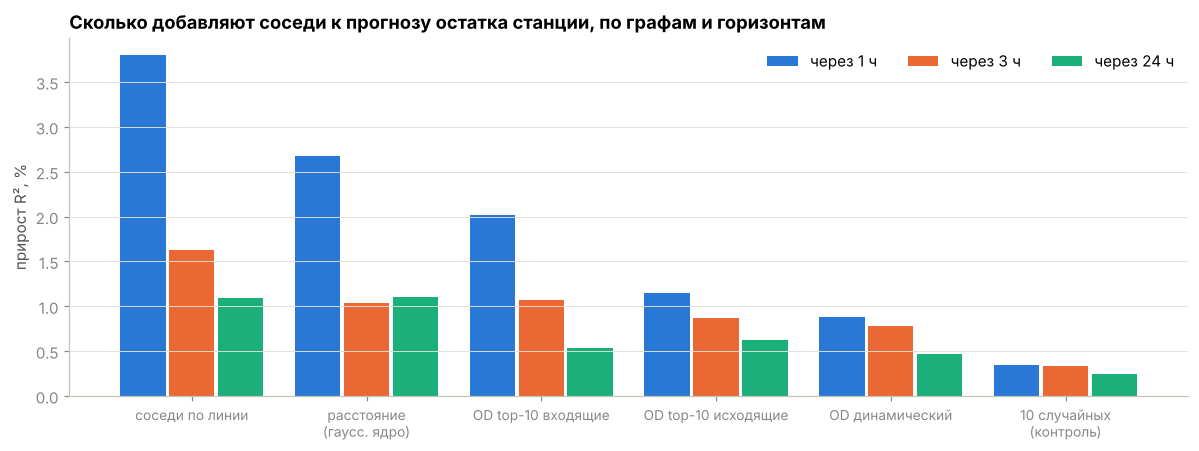

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
order = sp_tab.index.tolist()
xpos = np.arange(len(order))
wbar = 0.26
for j, h in enumerate(H):
    vals = sp_tab[f"+R² через {h} ч"].values * 100
    ax.bar(xpos + (j - 1) * (wbar + 0.02), vals, wbar, color=COL[j], label=f"через {h} ч")
ax.set_xticks(xpos, [o.replace(" (", "\n(") for o in order], fontsize=9)
ax.set_ylabel("прирост R², %")
ax.set_title("Сколько добавляют соседи к прогнозу остатка станции, по графам и горизонтам")
ax.legend(ncol=3, loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 5. Внешние факторы: погода, праздники, особые дни

Сухой обычный день: норма 4 недель ниже факта на 2.3% — она отстаёт от роста спроса
Снег > 10 см: 2 дня, медиана -51%


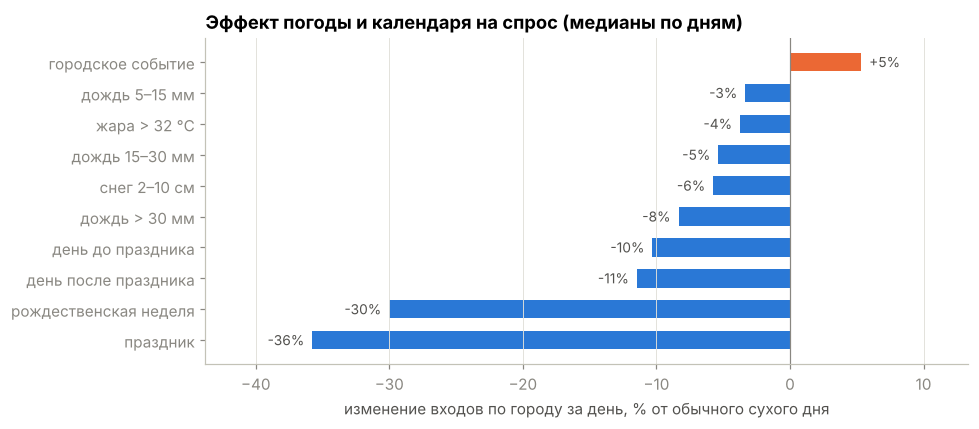

In [7]:
dev = np.log(Yd.sum(axis=1) / Nd.sum(axis=1))
dev = dev[dev.index >= "2023-02-01"]
def daily_weather(w):
    w = w[(w.index.hour >= 6) & (w.index.hour <= 22)]
    g = w.groupby(w.index.normalize())
    return pd.DataFrame({"precip": g["precipitation"].sum(min_count=1), "snow": g["snowfall"].sum(min_count=1),
                         "tmax": g["temperature_2m"].max()})
cd = cal.groupby(cal.index.normalize()).agg(hol=("is_holiday", "max"), dow=("dow", "first"),
     bef=("is_day_before_holiday", "max"), aft=("is_day_after_holiday", "max"),
     xmas=("xmas_week", "max"), cityev=("is_city_event", "max"))
df = pd.concat([dev.rename("dev"), daily_weather(X), cd], axis=1, sort=True).dropna()
base = df[(df.hol == 0) & (df.xmas == 0)]
pct = lambda s: (np.exp(s.median()) - 1) * 100
dry = pct(base.loc[base.precip < 0.5, "dev"])          # норма отстаёт от роста спроса: считаем от сухого дня
eff = {
    "дождь 5–15 мм": pct(base.loc[base.precip.between(5, 15), "dev"]) - dry,
    "дождь 15–30 мм": pct(base.loc[base.precip.between(15, 30), "dev"]) - dry,
    "дождь > 30 мм": pct(base.loc[base.precip > 30, "dev"]) - dry,
    "снег 2–10 см": pct(base.loc[base.snow.between(2, 10), "dev"]) - dry,
    "жара > 32 °C": pct(base.loc[base.tmax > 32, "dev"]) - dry,
    "день до праздника": pct(df.loc[df.bef == 1, "dev"]) - dry,
    "день после праздника": pct(df.loc[df.aft == 1, "dev"]) - dry,
    "рождественская неделя": pct(df.loc[df.xmas == 1, "dev"]) - dry,
    "праздник": pct(df.loc[df.hol == 1, "dev"]) - dry,
    "городское событие": pct(df.loc[df.cityev == 1, "dev"]) - dry,
}
print(f"Сухой обычный день: норма 4 недель ниже факта на {dry:.1f}% — она отстаёт от роста спроса")
print(f"Снег > 10 см: {len(base[base.snow > 10])} дня, медиана {pct(base.loc[base.snow > 10, 'dev']) - dry:+.0f}%")
e = pd.Series(eff).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(e.index, e.values, color=[COL[0] if v < 0 else COL[1] for v in e.values], height=0.6)
for yv, v in enumerate(e.values):
    ax.text(v + (0.6 if v >= 0 else -0.6), yv, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", color=INK2, fontsize=9)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("изменение входов по городу за день, % от обычного сухого дня")
ax.set_title("Эффект погоды и календаря на спрос (медианы по дням)")
ax.grid(axis="y", visible=False)
ax.set_xlim(e.min() - 8, max(e.max(), 0) + 8)
plt.tight_layout(); plt.show()

In [8]:
both = pd.concat([df, daily_weather(FC).add_suffix("_f")], axis=1, sort=True).dropna()
both = both[(both.hol == 0) & (both.xmas == 0)]
def design(t, s=""):
    return np.c_[np.ones(len(t)), np.log1p(t["precip" + s]), np.log1p(10 * t["snow" + s]),
                 np.minimum(t["tmax" + s], 5), np.maximum(t["tmax" + s] - 28, 0), (t.dow >= 5)]
tr, ev_ = both[both.index <= TRAIN_END], both[both.index > TRAIN_END]
for nm, s in [("фактическая", ""), ("прогноз на сутки", "_f")]:
    b = np.linalg.lstsq(design(tr, s), tr.dev, rcond=None)[0]
    e1 = ev_.dev - design(ev_, s) @ b
    print(f"Погода {nm}: R² дневного отклонения спроса по городу на val+test = {1 - (e1**2).sum() / ((ev_.dev - ev_.dev.mean())**2).sum():.2f}")

Погода фактическая: R² дневного отклонения спроса по городу на val+test = 0.16
Погода прогноз на сутки: R² дневного отклонения спроса по городу на val+test = 0.09


## 6. События на площадках

Отношение входов на станциях у площадки к норме в окне от −1 до +4 ч от начала события. Норма за 4 недели
сама частично содержит матчи прошлых недель, поэтому эффект здесь скорее занижен.

In [9]:
ev = pd.read_csv(RAW / "events.csv", parse_dates=["start"])
KV = {"mlb_yankees": "Yankee Stadium", "mlb_mets": "Citi Field / USTA", "usopen_main": "Citi Field / USTA",
      "usopen_fanweek": "Citi Field / USTA", "milb_cyclones": "Maimonides Park", "nba_nets": "Barclays Center",
      "wnba_liberty": "Barclays Center"}
ev = ev[(ev.start >= "2023-02-01") & (ev.start <= Y.index[-1])]
NORM_df = pd.DataFrame(NORM, index=Y.index, columns=Y.columns)
rows = []
for (kind, status), g in ev.groupby(["kind", "status"]):
    sids = st.loc[st.venue == KV[kind], "station_complex_id"].tolist()
    rat = []
    for t in g.start.dt.floor("h"):
        win = pd.date_range(t - pd.Timedelta(hours=1), t + pd.Timedelta(hours=4), freq="h").intersection(Y.index)
        a, b = Y.loc[win, sids].values.sum(), np.nansum(NORM_df.loc[win, sids].values)
        if b > 0:
            rat.append(a / b)
    rows.append({"событие": kind, "статус": status, "событий": len(rat), "входы / норма": np.median(rat)})
display(pd.DataFrame(rows).pivot(index="событие", columns="статус", values="входы / норма").round(2))

статус,cancelled,final,postponed
событие,,,
milb_cyclones,0.79,1.16,0.84
mlb_mets,NaN,4.75,0.47
mlb_yankees,NaN,3.68,0.94
nba_nets,NaN,1.69,NaN
usopen_fanweek,NaN,3.89,NaN
usopen_main,NaN,1.76,NaN
wnba_liberty,NaN,1.45,0.79


## 7. Закрытия: что предсказуемо заранее

Признаки `closure_lag` известны в 00:00. Смотрим вероятность, что станция закрыта сегодня, в зависимости от
длины серии закрытия до вчера и от закрытия в тот же день неделю назад.

In [10]:
cl = pd.read_parquet(PROCESSED / "closure_lag.parquet")
cday = C.groupby(day).max()
long = cday.stack().rename("closed").reset_index()
long.columns = ["date", "station_complex_id", "closed"]
long["station_complex_id"] = long["station_complex_id"].astype(str)
m = cl.merge(long, on=["date", "station_complex_id"])
m["серия до вчера, дней"] = pd.cut(m.closed_run_days, [-1, 0, 1, 2, 3, 7, 30, 1e6], labels=["0", "1", "2", "3", "4–7", "8–30", ">30"])
display(m.groupby("серия до вчера, дней", observed=True)["closed"].agg(["size", "mean"])
         .rename(columns={"size": "станционных дней", "mean": "P(закрыта сегодня)"}).round(3))
yday = (m.loc[m.closed_run_days == 1, "date"] - pd.Timedelta(days=1)).dt.dayofweek
print("Одиночный закрытый день вчера — по дню недели (0 = пн):", yday.value_counts().sort_index().to_dict())

lw = cday.shift(7)
rows = []
for d_, nm in [(5, "суббота"), (6, "воскресенье"), (0, "понедельник"), (2, "среда")]:
    mm = cday.index.dayofweek == d_
    a, b = cday[mm].values, lw[mm].values
    ok = ~pd.isna(b)
    a, b = a[ok].astype(bool), b[ok].astype(bool)
    rows.append({"день": nm, "P(закрыта)": a.mean(), "P(закрыта | закрыта неделю назад)": a[b].mean(),
                 "доля закрытий, предсказанных «неделю назад»": (a & b).sum() / max(a.sum(), 1)})
display(pd.DataFrame(rows).set_index("день").round(3))
first = (cday & ~cday.shift(1, fill_value=False)).values.sum()
print(f"Закрытых станционных дней {int(cday.values.sum()):,}, из них первых дней серии {int(first):,} — их заранее не видно")

,станционных дней,P(закрыта сегодня)
"серия до вчера, дней",,
0,568520,0.007
1,3840,0.944
2,3622,0.061
3,221,0.231
4–7,174,0.925
8–30,478,0.964
>30,1057,0.984


Одиночный закрытый день вчера — по дню недели (0 = пн): {0: 25, 1: 1, 2: 1, 3: 9, 4: 21, 5: 3689, 6: 94}


,P(закрыта),P(закрыта | закрыта неделю назад),"доля закрытий, предсказанных «неделю назад»"
день,,,
суббота,0.049,0.380,0.379
воскресенье,0.049,0.385,0.384
понедельник,0.006,0.474,0.474
среда,0.003,0.824,0.824


Закрытых станционных дней 9,563, из них первых дней серии 3,893 — их заранее не видно


## 8. Дрейф: тест против того же периода годом раньше

In [11]:
a = Y[(Y.index >= "2025-07-01") & (Y.index <= "2025-09-24 23:00")].where(~C).mean()
b = Y[Y.index >= "2026-07-01"].where(~C).mean()
city_ratio = b.sum() / a.sum()
rel = (b / a / city_ratio).dropna()
print(f"Город: тест / год назад = {city_ratio:.3f}")
print(f"Станций с изменением сверх города > 30%: {(np.abs(np.log(rel)) > np.log(1.3)).sum()}, > 20%: {(np.abs(np.log(rel)) > np.log(1.2)).sum()}")
drift = pd.DataFrame({"станция": name.reindex(rel.index), "тест / год назад (отн. города)": rel.round(2)})
display(pd.concat([drift.nsmallest(6, "тест / год назад (отн. города)"), drift.nlargest(6, "тест / год назад (отн. города)")]))

Город: тест / год назад = 1.015
Станций с изменением сверх города > 30%: 3, > 20%: 16


,станция,тест / год назад (отн. города)
station_complex_id,,
384,Burnside Av (4),0.73
455,69 St (7),0.73
365,Castle Hill Av (6),0.75
188,"Euclid Av (A,C)",0.78
224,57 St (M),0.78
87,"Crescent St (J,Z)",0.80
207,Beach 36 St (A),1.30
196,Aqueduct Racetrack (A),1.29
22,"Rector St (R,W)",1.26


## 9. Выводы для моделей

1. **Нижняя планка** — медиана того же часа за 4 недели, а не «неделю назад»: на тесте она заметно сильнее.
   Норма систематически отстаёт от растущего спроса (≈ 2%) — модели нужна подстройка уровня.
2. **Около трети ошибки нормы — уровень дня**, остальное — форма суток. Больше половины дневного отклонения
   станции общее для всего города → разумна двухуровневая схема: городской уровень дня (календарь, погода)
   + станционная поправка.
3. **Пространственные связи есть, но работают на коротком горизонте.** Соседи по линии и по расстоянию
   добавляют к прогнозу на 1 ч в 8–11 раз больше случайного контроля (≈ 3–4% R²), на 24 ч — в 2–4 раза,
   но абсолютный прирост там около 1%. OD-граф слабее географических; динамический OD по этому критерию не лучше статического.
   Следствие для постановки: кроме прогноза на сутки нужна задача внутридневного прогноза (1–3 ч), где
   пространственная составляющая реально окупается.
4. **Погода** даёт единицы процентов (кроме сильного снега); прогноз погоды на сутки сохраняет только часть
   её пользы. В признаки — `precipitation`, `snowfall`, температура; `rain` в прогнозе почти пуст до 2025 года.
5. **События на площадках** — самый сильный локальный фактор (бейсбол — входы в 3,5–5 раз выше нормы).
   Перенесённые матчи всплеска не дают — это ожидаемые ошибки по расписанию, разбирать отдельно.
6. **Закрытия** в основном выходные: закрытие в субботу почти всегда продолжается в воскресенье, в понедельник
   станция открывается. Полезный признак — «закрыта в тот же день неделю назад» (сдвиг маски на 7 дней,
   известен заранее): он предсказывает 38% выходных закрытий. Первый день закрытия заранее не виден.
7. **Дрейф** между обучением и тестом небольшой: единицы станций меняются сверх города больше чем на 30%.